In [64]:
import time
from pathlib import Path
import jax

import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)
from mGST.utility_functions_comparisons import get_target_operators_gate_set_name, get_compressed_rep_from_mgst_output, kraus_tensor_to_mgst, get_initial_gate_set_for_optimization
from mGST.simulate import apply_noisy_kraus_tensors_to_target_gate_set, get_random_noisy_kraus_tensors_for_gate_set, generate_sequence_indices, compute_probability_matrices, run_optimization_workflow
from mGST.typing import TrustRegionOptions, OperatorSchedule

from mGST.visualization import plot_cost_function

# Parameters common to all optimization

In [ ]:
num_gates, kraus_rank, dim = 6, 4, 4

# Parameter options
DATA = Path("identifiability_and_cramer_rao/data")
DESIGNS = {"A": (0.3, 600, 2200, 28), "B": (0.05, 400, 150, 32), "07": (0.05, 400, 1000, 14)}  # noise strength, N, m, L_max
SETTINGS = {"default": (1.0, 20, 1e-3), "tight": (0.02, 60, 1e-3), "conv": (1e-4, 60, 1e-8)}    # abs. tolerance, outer iterations, rel. precision

target_operators, _ = get_target_operators_gate_set_name(gate_set_name="2QXYICZ")

target_superops = {"kraus": kraus_tensor_to_mgst(target_operators["kraus"]), "povm": target_operators["povm"], "state": target_operators["state"]}

init = get_initial_gate_set_for_optimization(
    target_superops=target_superops,
    kraus_rank=kraus_rank,
    state_rank=dim,
    povm_rank=dim,
    spam_depolarization=1e-2,
    project_kraus_to_isometry=True)

# This will not change across settings
tr_options = TrustRegionOptions(num_iterations=5, verbose=False, verbose_cg=False, num_iterations_cg=10, tol_grad=1e-8, radius_heuristic="typical_distance")

# Design: A

In [42]:
# Choosing the mode for this run
design, r = "A", 4

noise_strength, num_sequences, num_samples, max_circuit_depth = DESIGNS[design]
print("Parameters used in design:")
print(f"Num. Sequences: {num_sequences}")
print(f"Num. Samples: {num_samples}")
print(f"Max Circuit Depth: {max_circuit_depth}")
print(f"Noise Strength: {noise_strength}")

Parameters used in design:
Num. Sequences: 600
Num. Samples: 2200
Max Circuit Depth: 28
Noise Strength: 0.3


In [ ]:
# truth, target, initial point
noise = get_random_noisy_kraus_tensors_for_gate_set(num_gates=num_gates, dim=dim, rank_kraus=kraus_rank, noise_strength=noise_strength, seed=42)

noisy_superop = apply_noisy_kraus_tensors_to_target_gate_set(kraus_tensors_noisy=noise, target_gate_set=target_operators, is_target_vectorized=True)

K, A, B = get_compressed_rep_from_mgst_output(*noisy_superop.values(), kraus_rank=kraus_rank, state_rank=dim, povm_rank=dim)

true_psd = {"kraus": K, "povm": A, "state": B}

INFO:2026-11-18 23:21:33,552:jax._src.xla_bridge:927: Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
2026-11-18 23:21:33,552 - jax._src.xla_bridge - INFO - Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:2026-11-18 23:21:33,559:jax._src.xla_bridge:927: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/

In [ ]:
# design and data
indices_dict = generate_sequence_indices(num_gates=num_gates, num_circuits=num_sequences, seq_len_list=[1, max(3, max_circuit_depth // 2 + 1), max_circuit_depth], seed=12345)
probability_matrices = compute_probability_matrices(K, A, B, gate_indices=indices_dict["gate_indices"], num_shots=num_samples, seed=1000 + r)

## Setting: conv

In [25]:
setting = "conv"
tol, num_outer, rel = SETTINGS[setting]
print("Setting: ", setting)
print(f"Tolerance: {tol}, Num Outer: {num_outer}, Relative Precision: {rel}")
# optimizer

schedule = OperatorSchedule.default(num_outer, tr_options)
options = {"schedule": {op: schedule for op in ["povm", "kraus", "state"]}, "num_iterations_outer": num_outer, "relative_precision": rel,
           "global_gradient_norm_tol": 1e-10, "noise_threshold": None, "compute_least_squares": 1,
           "optimization_verbose": True,  # True to watch the iterations
           "absolute_tolerance": tol}

Setting:  conv
Tolerance: 0.0001, Num Outer: 60, Relative Precision: 1e-08


In [10]:
t0 = time.time()
result = run_optimization_workflow(num_shots=num_samples, init_operators=init, operators_psd_true=true_psd, target_superops=target_superops,
                                   optimization_options=options, use_log_likelihood=True, indices_dict=indices_dict,
                                   probability_matrices=probability_matrices, gauge_optimize=False)

print(f"{time.time() - t0:.0f} s, {result['convergence_reason']}")

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
povm: Schedule:
  [0-59]: TrustRegionOptions
kraus: Schedule:
  [0-59]: TrustRegionOptions
state: Schedule:
  [0-59]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-08 
+ Absolute Tolerance 📉 1.00e-04 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.598909e+06
 * jitted objective: yes (prefix contraction)
👾 Least squares value after POVM: 2.298270e-03 👾
👾 Least squares value after Kraus: 6.818968e-04 👾
👾 Least squares value after State at iteration 1: 6.318219e-04 👾
🏁 Iteration: 1/60. f(x): 1.609056e+06.

 🎯 Relative change in reducible cost over iteration 1: 9.32e-01. Target: 1.00e-08.
 📉 Decrease over iteration 1: 1.39e+05. Estimated remaining decrease: inf. Target: 1.00e-04.
👾 Least squares value after POVM: 3.797764e-04 👾
👾 Least squares value after Kraus: 2.318074e-04 👾
👾 Least squares value af

## Setting: default

In [26]:
setting = "default"
tol, num_outer, rel = SETTINGS[setting]
print("Setting: ", setting)
print(f"Tolerance: {tol}, Num Outer: {num_outer}, Relative Precision: {rel}")
# optimizer

schedule_default = OperatorSchedule.default(num_outer, tr_options)
options_default = {"schedule": {op: schedule_default for op in ["povm", "kraus", "state"]}, "num_iterations_outer": num_outer, "relative_precision": rel,
           "global_gradient_norm_tol": 1e-10, "noise_threshold": None, "compute_least_squares": 1,
           "optimization_verbose": True,  # True to watch the iterations
           "absolute_tolerance": tol}

Setting:  default
Tolerance: 1.0, Num Outer: 20, Relative Precision: 0.001


In [ ]:
t0 = time.time()
result_default = run_optimization_workflow(
    num_shots=num_samples,
    init_operators=init,
    operators_psd_true=true_psd,
    target_superops=target_superops,
    optimization_options=options_default,
    use_log_likelihood=True,
    indices_dict=indices_dict,
    probability_matrices=probability_matrices,
    gauge_optimize=False)

print(f"{time.time() - t0:.0f} s, {result_default['convergence_reason']}")

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
povm: Schedule:
  [0-19]: TrustRegionOptions
kraus: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.598909e+06
 * jitted objective: yes (prefix contraction)
👾 Least squares value after POVM: 2.298270e-03 👾
👾 Least squares value after Kraus: 6.818968e-04 👾
👾 Least squares value after State at iteration 1: 6.318219e-04 👾
🏁 Iteration: 1/20. f(x): 1.609056e+06.

 🎯 Relative change in reducible cost over iteration 1: 9.32e-01. Target: 1.00e-03.
 📉 Decrease over iteration 1: 1.39e+05. Estimated remaining decrease: inf. Target: 1.00e+00.
👾 Least squares value after POVM: 3.797764e-04 👾
👾 Least squares value after Kraus: 2.318074e-04 👾
👾 Least squares value af

# Design: 07 (baseline)

In [47]:
# Choosing the mode for this run
design_baseline, r = "07", 4
noise_strength, num_sequences, num_samples, max_circuit_depth = DESIGNS[design_baseline]
print("Parameters used in design:")
print(f"Num. Sequences: {num_sequences}")
print(f"Num. Samples: {num_samples}")
print(f"Max Circuit Depth: {max_circuit_depth}")
print(f"Noise Strength: {noise_strength}")

# truth, target, initial point
noise_baseline = get_random_noisy_kraus_tensors_for_gate_set(num_gates=num_gates, dim=dim, rank_kraus=kraus_rank, noise_strength=noise_strength, seed=42)

noisy_superop_baseline = apply_noisy_kraus_tensors_to_target_gate_set(kraus_tensors_noisy=noise_baseline, target_gate_set=target_operators, is_target_vectorized=True)

K, A, B = get_compressed_rep_from_mgst_output(*noisy_superop_baseline.values(), kraus_rank=kraus_rank, state_rank=dim, povm_rank=dim)

true_psd_baseline = {"kraus": K, "povm": A, "state": B}

Parameters used in design:
Num. Sequences: 400
Num. Samples: 1000
Max Circuit Depth: 14
Noise Strength: 0.05


In [48]:
# design and data
indices_dict_baseline = generate_sequence_indices(num_gates=num_gates, num_circuits=num_sequences, seq_len_list=[1, max(3, max_circuit_depth // 2 + 1), max_circuit_depth], seed=12345)

probability_matrices_baseline = compute_probability_matrices(K, A, B, gate_indices=indices_dict_baseline["gate_indices"], num_shots=num_samples, seed=1000 + r)

In [49]:
t0 = time.time()
result_default_baseline = run_optimization_workflow(
    init_operators=init,
    target_superops=target_superops,
    optimization_options=options_default, #change for different optimization options
    use_log_likelihood=True,
    gauge_optimize=False,
    num_shots=num_samples, # change this
    operators_psd_true=true_psd_baseline, # change this
    indices_dict=indices_dict_baseline, # change this
    probability_matrices=probability_matrices_baseline, # change this
    )

print(f"{time.time() - t0:.0f} s, {result_default_baseline['convergence_reason']}")

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
povm: Schedule:
  [0-19]: TrustRegionOptions
kraus: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 3.780631e+05
 * jitted objective: yes (prefix contraction)
👾 Least squares value after POVM: 3.017853e-04 👾
👾 Least squares value after Kraus: 1.347900e-04 👾
👾 Least squares value after State at iteration 1: 1.324358e-04 👾
🏁 Iteration: 1/20. f(x): 3.786992e+05.

 🎯 Relative change in reducible cost over iteration 1: 8.36e-01. Target: 1.00e-03.
 📉 Decrease over iteration 1: 3.23e+03. Estimated remaining decrease: inf. Target: 1.00e+00.
👾 Least squares value after POVM: 1.300104e-04 👾
👾 Least squares value after Kraus: 1.281584e-04 👾
👾 Least squares value af

# Design: B

In [79]:
# Choosing the mode for this run
design_B, r = "B", 4
noise_strength, num_sequences, num_samples, max_circuit_depth = DESIGNS[design_B]

print("Parameters used in design:")
print(f"Num. Sequences: {num_sequences}")
print(f"Num. Samples: {num_samples}")
print(f"Max Circuit Depth: {max_circuit_depth}")
print(f"Noise Strength: {noise_strength}")

# the true operators are the same as for the baseline design

# design and data
indices_dict_B = generate_sequence_indices(num_gates=num_gates, num_circuits=num_sequences, seq_len_list=[1, max(3, max_circuit_depth // 2 + 1), max_circuit_depth], seed=12345)

probability_matrices_B = compute_probability_matrices(K, A, B, gate_indices=indices_dict_B["gate_indices"], num_shots=num_samples, seed=1000 + r)

Parameters used in design:
Num. Sequences: 400
Num. Samples: 150
Max Circuit Depth: 32
Noise Strength: 0.05


In [80]:
t0 = time.time()
result_default_B = run_optimization_workflow(
    init_operators=init,
    target_superops=target_superops,
    optimization_options=options_default, #change for different optimization options
    use_log_likelihood=True,
    gauge_optimize=False,
    num_shots=num_samples, # change this
    operators_psd_true=true_psd_baseline, # change this
    indices_dict=indices_dict_B, # change this
    probability_matrices=probability_matrices_B, # change this
    )

print(f"{time.time() - t0:.0f} s, {result_default_B['convergence_reason']}")

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
povm: Schedule:
  [0-19]: TrustRegionOptions
kraus: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 5.930530e+04
 * jitted objective: yes (prefix contraction)
👾 Least squares value after POVM: 1.283345e-03 👾
👾 Least squares value after Kraus: 8.434551e-04 👾
👾 Least squares value after State at iteration 1: 8.412506e-04 👾
🏁 Iteration: 1/20. f(x): 5.981283e+04.

 🎯 Relative change in reducible cost over iteration 1: 5.85e-01. Target: 1.00e-03.
 📉 Decrease over iteration 1: 7.14e+02. Estimated remaining decrease: inf. Target: 1.00e+00.
👾 Least squares value after POVM: 8.350281e-04 👾
👾 Least squares value after Kraus: 8.264470e-04 👾
👾 Least squares value af

# Visualization

In [59]:
title_common = rf"2Q | [$r_K, r_A, r_B$] = [{kraus_rank}, {dim}, {dim}]"

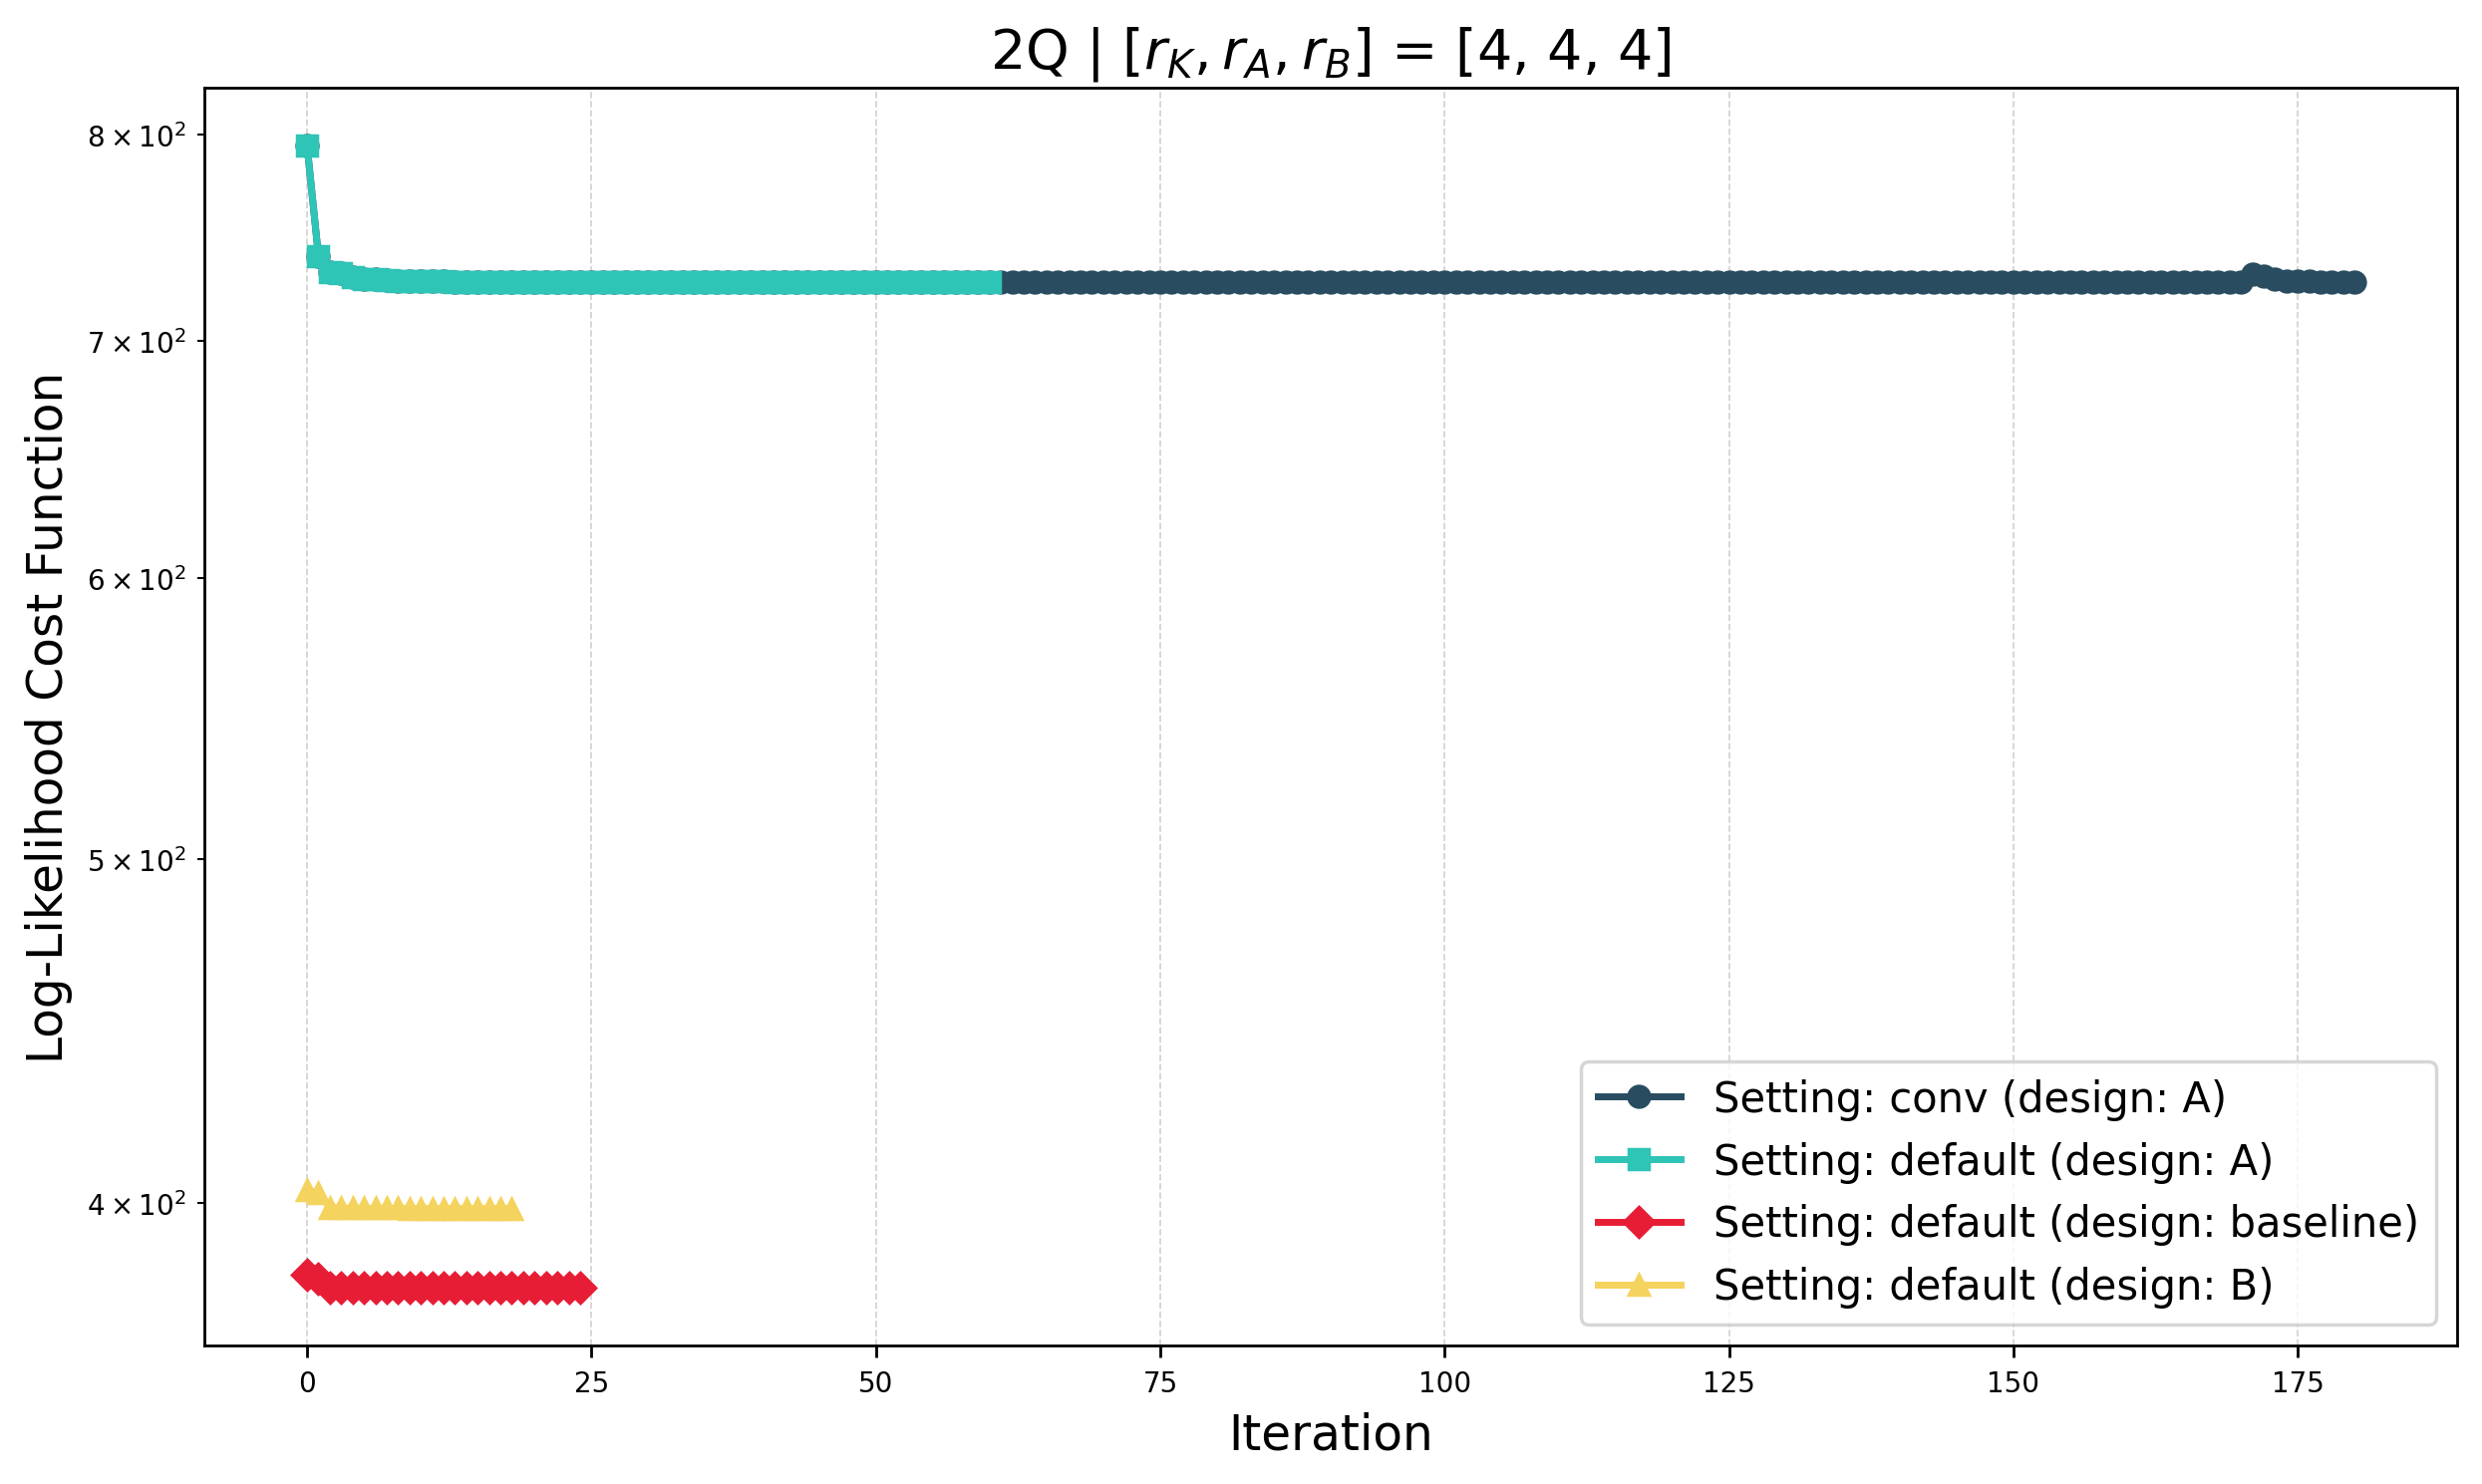

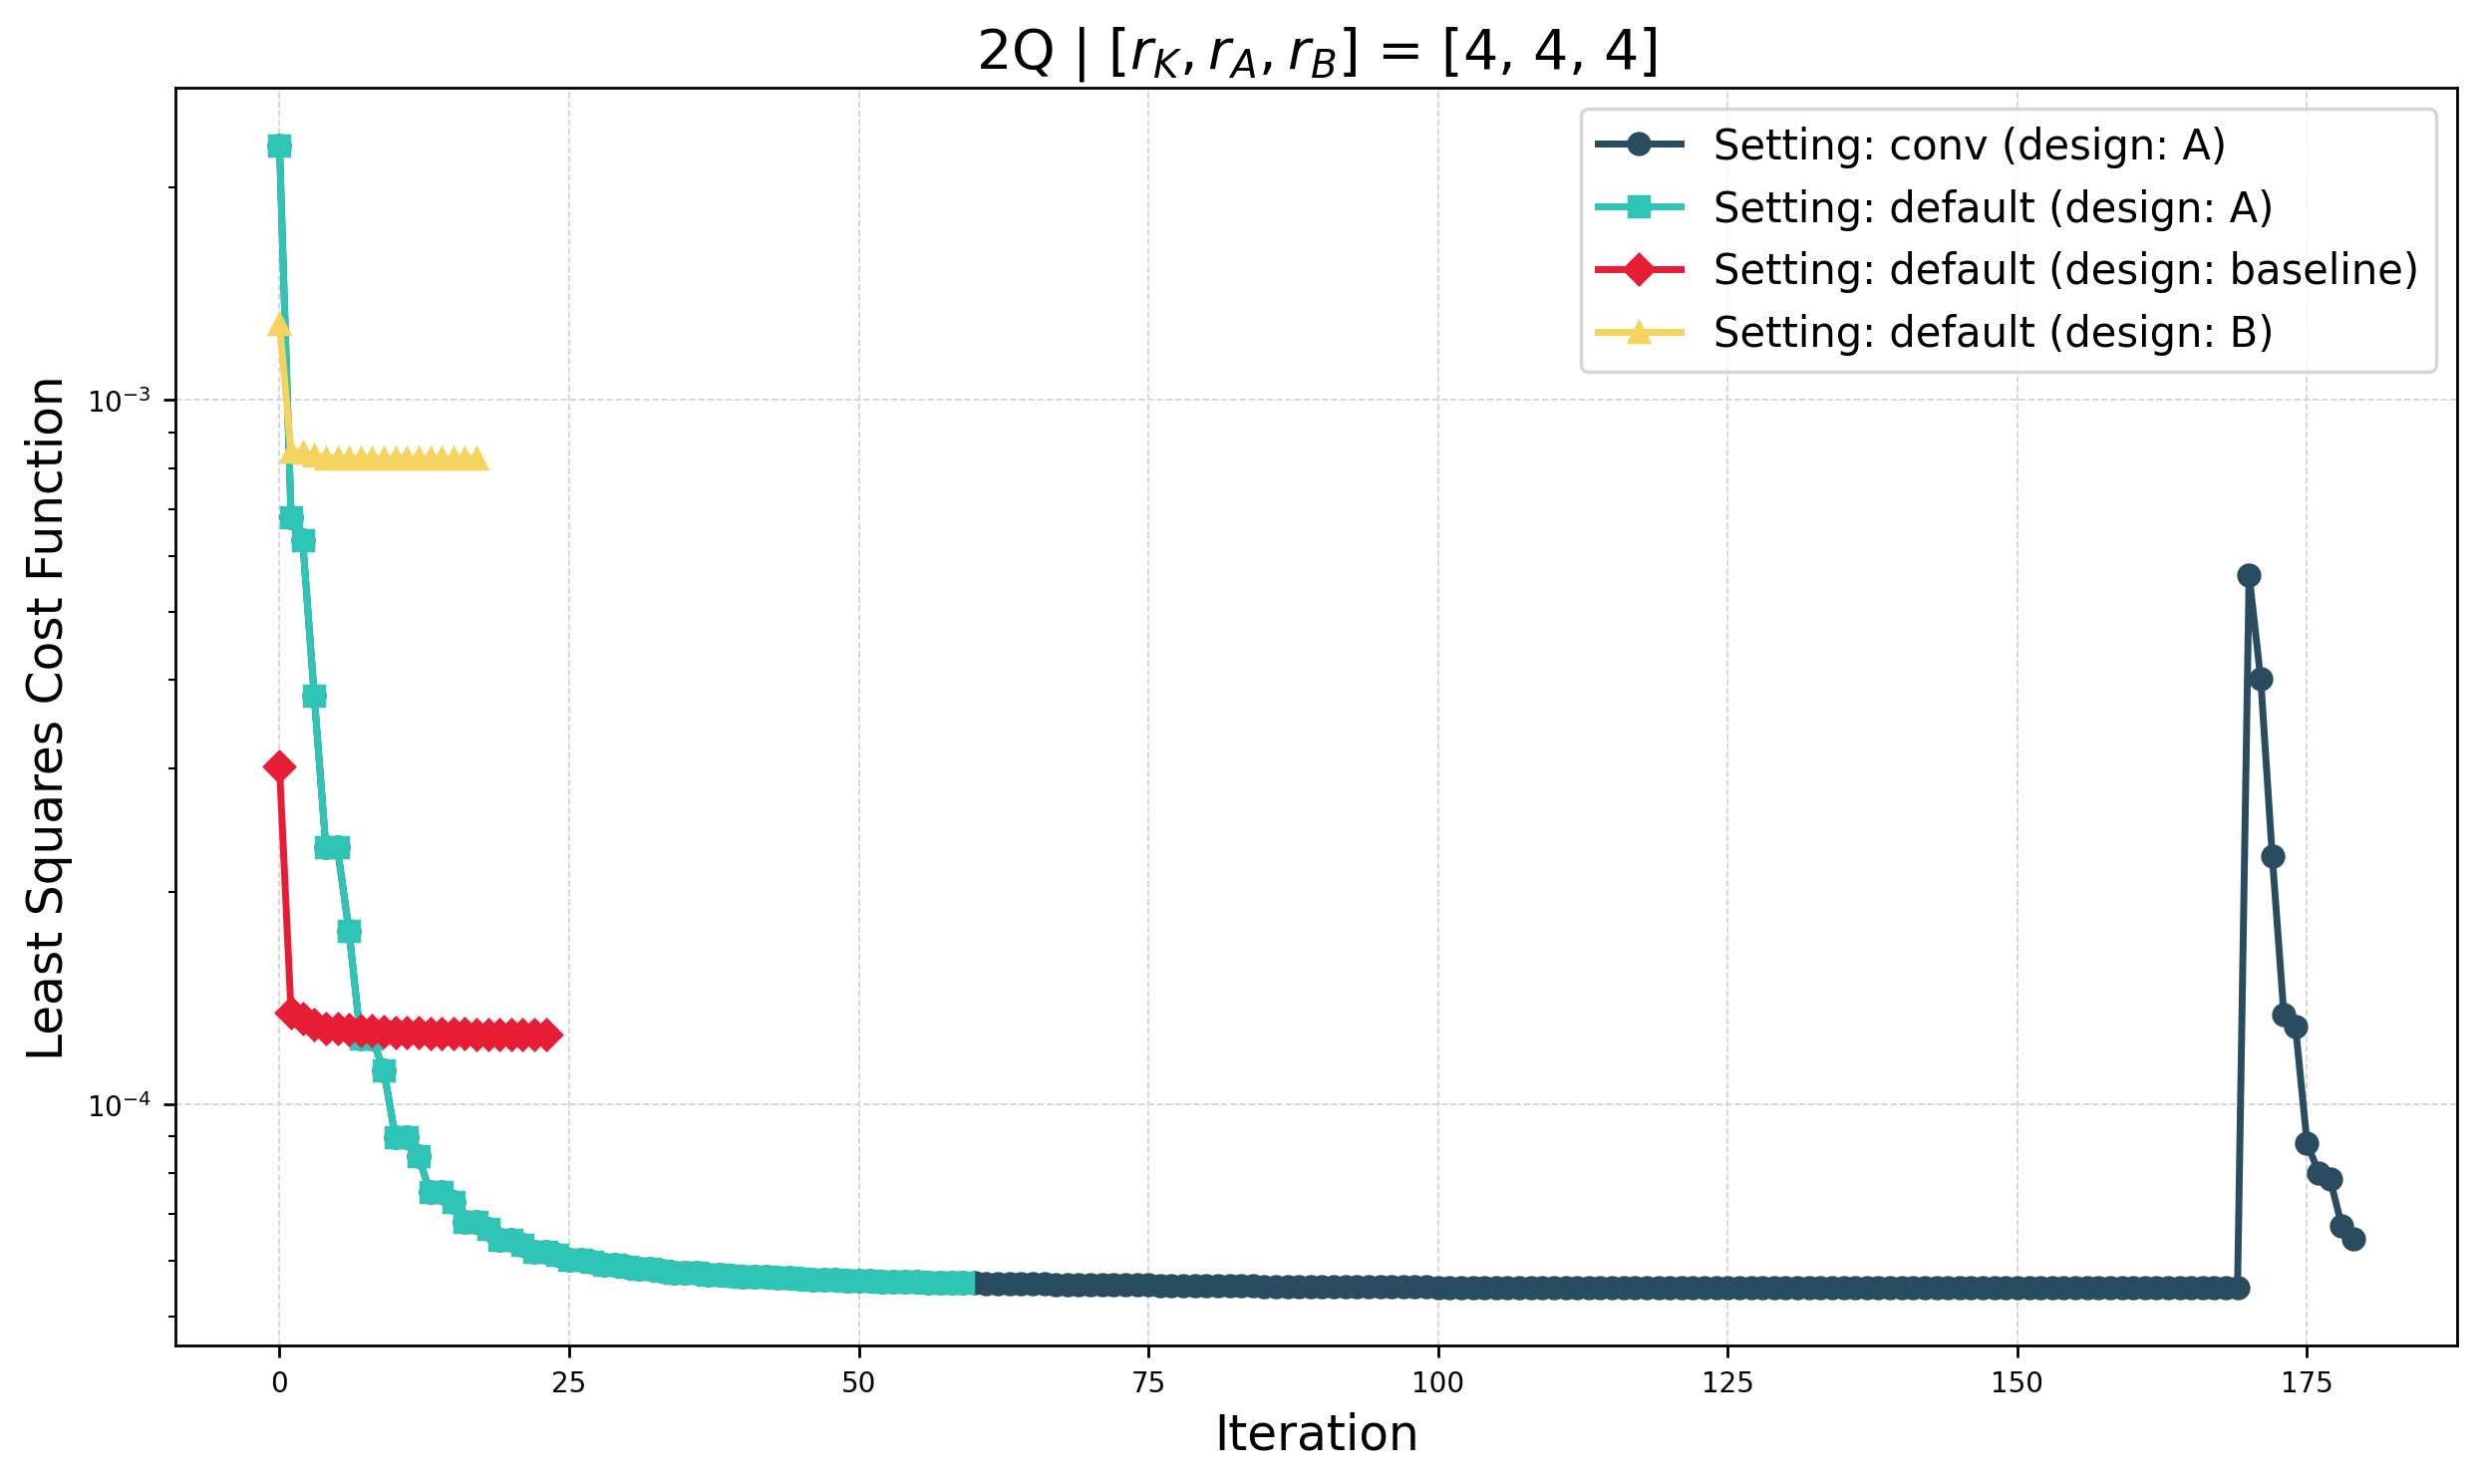

In [82]:
# Plot the cost function history of the optimization result
results = [result, result_default, result_default_baseline, result_default_B]
# we can "normalize the loglikelihood based on shots"

num_shots_list = [2200, 2200, 1000, 150]

cost_histories_loglikelihood = [jnp.array(res["cost_fn_history"]["main"])/num_shots for res, num_shots in zip(results, num_shots_list)]
cost_histories_least_squares = [res["cost_fn_history"]["least_squares"] for res in results]

labels = ["Setting: conv (design: A)", "Setting: default (design: A)", "Setting: default (design: baseline)", "Setting: default (design: B)"]

idx = 0

plot_cost_function(cost_histories_loglikelihood[idx:], labels=labels[idx:], ylabel="Log-Likelihood Cost Function", title=title_common)
plot_cost_function(cost_histories_least_squares[idx:], labels=labels[idx:], ylabel="Least Squares Cost Function", title=title_common)

In [72]:
# check against the saved run (07 baseline: DATA / "crb_estimates" / f"{'converged' if setting == 'conv' else 'default'}_{r}.npz")
saved = jnp.load(DATA / "ptm_refits" / f"{setting}_s{noise_strength}_N{num_sequences}_m{num_samples}_L{max_circuit_depth}_d12345_r{r}.npz")
print("final cost", float(result["cost_fn_history"]["main"][-1]), "saved", float(saved["final_cost"]))

FileNotFoundError: [Errno 2] No such file or directory: 'identifiability_and_cramer_rao/data/ptm_refits/default_s0.05_N400_m1000_L14_d12345_r4.npz'